# Inspect World Model

Qualitative companion to `eval_world_model.py`'s accuracy-vs-N plot (see
`blueprints/WORLDMODEL.md`, *Qualitative Path Inspection*). Picks one real eval
episode with a genuine revisit event and renders a strip of frames -- one
column per timestep -- spanning the agent leaving a spot and returning to it,
**four rows**:

1. **original** -- raw frame from the recording
2. **tokenizer recon** -- the VQ-VAE's own reconstruction of the true tokens
   (the blur ceiling, independent of the world model -- without this row you
   can't tell "world model is wrong" from "tokenizer was always this blurry")
3. **world model, teacher-forced** -- true recorded history fed at *every*
   column, so errors don't compound between columns; shows raw one-step
   prediction quality
4. **world model, autoregressive** -- seeded with true history, then self-fed
   on its own predictions from then on (actions stay ground-truth throughout,
   since they're recorded, never generated). This is the row that can show
   the "dementia" failure: once it's past `H` self-generated steps, no real
   information about a revisited room survives anywhere in its context.

The revisited column (`t2`, red border) is the one to look at.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # repo root, so `import src...` works

import glob
import numpy as np
import torch
from IPython.display import Image, display

from src.models.vqvae import VQVAE
from src.models.world_model import WorldModel
from src.utils.revisits import find_revisit_events
from src.utils.viz import save_path_strip

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


## Load the frozen tokenizer and the trained world model

In [2]:
tok_ckpt = torch.load("../checkpoints/tokenizer/latest.pt", map_location=DEVICE, weights_only=False)
tokenizer = VQVAE().to(DEVICE)
tokenizer.load_state_dict(tok_ckpt["model"])
tokenizer.eval()

wm_ckpt = torch.load("../checkpoints/worldmodel/latest.pt", map_location=DEVICE, weights_only=False)
H = wm_ckpt["args"]["history"]
model = WorldModel(history=H).to(DEVICE)
model.load_state_dict(wm_ckpt["model"])
model.eval()

print(f"tokenizer: step {tok_ckpt['step']}  |  world model: step {wm_ckpt['step']} (H={H})")


tokenizer: step 50000  |  world model: step 30000 (H=16)


## Pick an episode and a revisit event

Scans real eval episodes for a revisit event with `H < N <= 4H` -- clearly
past the model's context window, but not so large the strip becomes huge.
Raise `EPISODES_TO_SCAN` if none turns up in the first batch.

In [3]:
import random

EPISODES_TO_SCAN = 30   # how many eval episodes to search
PAD = 5                 # columns to show before t1 and after t2
SEED = None              # int for a reproducible pick; None = a different path every run

rng = random.Random(SEED)
paths = sorted(glob.glob("../data/tokens/eval/*.npz"))
rng.shuffle(paths)       # different episode order each run when SEED=None
paths = paths[:EPISODES_TO_SCAN]

chosen = None
for path in paths:
    with np.load(path) as d:
        pos = d["agent_pos"]
    candidates = [(t1, t2, n) for t1, t2, n in find_revisit_events(pos) if H < n <= 4 * H]
    if candidates:
        chosen = (path, *rng.choice(candidates))  # a random qualifying event, not just the first
        break

assert chosen, "no suitable revisit event found -- raise EPISODES_TO_SCAN"
path, t1, t2, n = chosen
stem = os.path.basename(path)
print(f"episode {stem}: t1={t1}  t2={t2}  N={n}  (H={H})")


episode 20220920T135115-1000.npz: t1=520  t2=557  N=37  (H=16)


## Load the data for the strip

`start` is clamped to `>= H` so there's always a full true window to seed
both row 3 (teacher-forced) and row 4's rollout (`seed_start = start - H`).

In [4]:
T_EPISODE = 1001

with np.load(path) as d:
    true_tokens = d["tokens"].astype(np.int64)      # (T,16)
    true_actions = d["action"].astype(np.float32)   # (T,6)

with np.load(os.path.join("../data/eval", stem)) as d:
    raw_images = d["image"]                          # (T,64,64,3) uint8

start = max(H, t1 - PAD)
end = min(t2 + PAD, T_EPISODE - 1)
seed_start = start - H
cols = list(range(start, end + 1))

print(f"rendering columns {start}..{end}  ({len(cols)} frames)  |  revisit at t2={t2}")


rendering columns 515..562  (48 frames)  |  revisit at t2=557


## Row 1 (original) and row 2 (tokenizer reconstruction)

In [5]:
row_raw = torch.from_numpy(raw_images[cols].transpose(0, 3, 1, 2)).float().div(255.0)

true_tok_cols = torch.from_numpy(true_tokens[cols]).to(DEVICE)
with torch.no_grad():
    row_recon = tokenizer.decode_indices(true_tok_cols).cpu()


## Row 3: world model, teacher-forced

At every column, feed the model the *true* recorded H steps before it and
generate that one frame -- independent per column, no compounding error.

In [6]:
row_tf = []
with torch.no_grad():
    for t in cols:
        tok_win = torch.from_numpy(true_tokens[t - H: t + 1]).unsqueeze(0).to(DEVICE)
        act_win = torch.from_numpy(true_actions[t - H: t + 1]).unsqueeze(0).to(DEVICE)
        pred = model.generate_last_frame(tok_win, act_win)
        row_tf.append(tokenizer.decode_indices(pred).cpu())
row_tf = torch.cat(row_tf, dim=0)


## Row 4: world model, autoregressive rollout

Seed a working buffer with the *true* tokens for the H steps ending at
`start`. From `start+1` onward, each new frame is generated from the buffer's
own previous entries -- which are themselves predictions once past `start`.
Actions are always the true recorded ones (given, never generated).

In [7]:
roll_tokens = true_tokens[seed_start: end + 1].copy()   # overwritten after `start`
roll_actions = true_actions[seed_start: end + 1]         # always true

with torch.no_grad():
    for t in range(start + 1, end + 1):
        i = t - seed_start
        tok_win = torch.from_numpy(roll_tokens[i - H: i + 1]).unsqueeze(0).to(DEVICE)
        act_win = torch.from_numpy(roll_actions[i - H: i + 1]).unsqueeze(0).to(DEVICE)
        roll_tokens[i] = model.generate_last_frame(tok_win, act_win)[0].cpu().numpy()

roll_idx = [t - seed_start for t in cols]
roll_tok_cols = torch.from_numpy(roll_tokens[roll_idx]).to(DEVICE)
with torch.no_grad():
    row_roll = tokenizer.decode_indices(roll_tok_cols).cpu()


## Render the strip

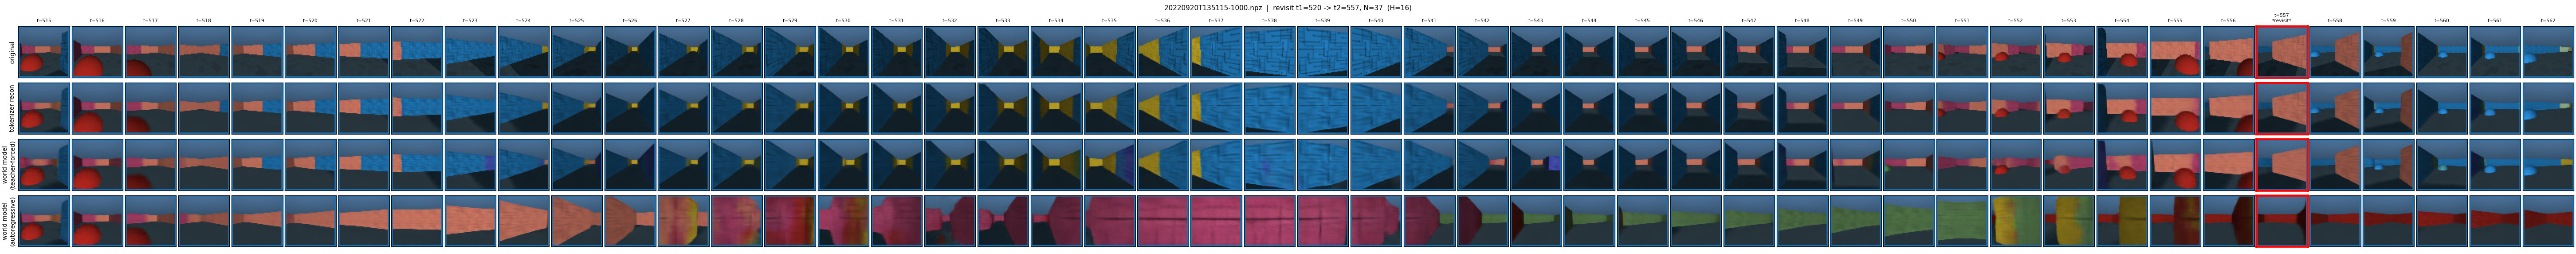

In [8]:
rows = [row_raw, row_recon, row_tf, row_roll]
row_labels = ["original", "tokenizer recon", "world model\n(teacher-forced)", "world model\n(autoregressive)"]
col_labels = [f"t={t}" + ("\n*revisit*" if t == t2 else "") for t in cols]
highlight_col = cols.index(t2)

out_path = f"../outputs/worldmodel/path_inspection_{stem.replace('.npz', '')}.png"
save_path_strip(
    rows, out_path, row_labels, col_labels=col_labels, highlight_col=highlight_col,
    title=f"{stem}  |  revisit t1={t1} -> t2={t2}, N={n}  (H={H})",
)
display(Image(filename=out_path))


## Reading this strip

Compare row 2 (tokenizer's own ceiling) to rows 3 and 4 at the highlighted
column. Row 3 (teacher-forced) had the true recent past handed to it, so it
measures one-step prediction quality alone. Row 4 (autoregressive) only knows
what it guessed for itself once past the seed (`t={start}` marks that seed
point in the printed range above) -- if by the revisit column it has drifted
and no longer matches row 2, while row 3 still does, that gap *is* the
context-window failure this project exists to fix with a cache.

## Export as video (long path)

The strip above is short (`PAD`-sized) so it fits on screen. For a real look
at drift over time, render a much longer path around the same revisit event
and save each row as its own `.mp4` under `outputs/videos/` -- easier to
actually watch than a wide static strip. Same four rows, same generation
logic as above, just over a longer range (`VIDEO_PAD`).

Row 4 (autoregressive) still needs one full 16-token generation per frame, so
a long path takes a while -- this is occasional, human-driven use, not part
of any training loop, so that's an acceptable trade.

In [9]:
VIDEO_PAD = 60   # much longer than the static strip's PAD
FPS = 8

video_start = max(H, t1 - VIDEO_PAD)
video_end = min(t2 + VIDEO_PAD, T_EPISODE - 1)
video_seed_start = video_start - H
video_cols = list(range(video_start, video_end + 1))

print(f"video range {video_start}..{video_end}  ({len(video_cols)} frames, "
      f"{len(video_cols) / FPS:.1f}s @ {FPS}fps)  |  revisit at t2={t2}")

video range 460..617  (158 frames, 19.8s @ 8fps)  |  revisit at t2=557


In [10]:
# rows 1+2: raw and tokenizer recon over the video range (cheap, no generation)
video_row_raw = torch.from_numpy(raw_images[video_cols].transpose(0, 3, 1, 2)).float().div(255.0)

video_true_tok_cols = torch.from_numpy(true_tokens[video_cols]).to(DEVICE)
with torch.no_grad():
    video_row_recon = tokenizer.decode_indices(video_true_tok_cols).cpu()

In [ ]:
# row 3: teacher-forced, same as before but over video_cols
video_row_tf = []
video_tf_tokens = []   # kept (not just decoded) so the numeric block below can score exact-match
with torch.no_grad():
    for t in video_cols:
        tok_win = torch.from_numpy(true_tokens[t - H: t + 1]).unsqueeze(0).to(DEVICE)
        act_win = torch.from_numpy(true_actions[t - H: t + 1]).unsqueeze(0).to(DEVICE)
        pred = model.generate_last_frame(tok_win, act_win)
        video_tf_tokens.append(pred[0].cpu().numpy())
        video_row_tf.append(tokenizer.decode_indices(pred).cpu())
video_row_tf = torch.cat(video_row_tf, dim=0)
video_tf_tokens = np.stack(video_tf_tokens)   # (len(video_cols), 16)


In [ ]:
# row 4: autoregressive rollout, same as before but over the longer video range
video_roll_tokens = true_tokens[video_seed_start: video_end + 1].copy()  # overwritten after video_start
video_roll_actions = true_actions[video_seed_start: video_end + 1]        # always true

with torch.no_grad():
    for t in range(video_start + 1, video_end + 1):
        i = t - video_seed_start
        tok_win = torch.from_numpy(video_roll_tokens[i - H: i + 1]).unsqueeze(0).to(DEVICE)
        act_win = torch.from_numpy(video_roll_actions[i - H: i + 1]).unsqueeze(0).to(DEVICE)
        video_roll_tokens[i] = model.generate_last_frame(tok_win, act_win)[0].cpu().numpy()

video_roll_idx = [t - video_seed_start for t in video_cols]
video_roll_tok_cols = torch.from_numpy(video_roll_tokens[video_roll_idx]).to(DEVICE)
with torch.no_grad():
    video_row_roll = tokenizer.decode_indices(video_roll_tok_cols).cpu()

## Numerical companion: per-timestep token accuracy

The videos show the rollout drifting; this puts a number on it. Per-timestep
exact-match accuracy over the 16 tokens, teacher-forced vs. autoregressive,
against the same `video_cols` range used for the videos above. Three markers:

- `t1` -- the agent leaves the spot.
- `pure_rollout_start = video_start + H` -- from here on the rollout's entire
  H-step context is self-generated; zero real tokens from the true trajectory
  remain anywhere in view.
- `t2` -- the revisit.

Teacher-forced is always handed the true recent past, so it's the ceiling
(one-step prediction quality, no compounding error) -- it should stay roughly
flat across the whole range. If the autoregressive curve tracks it before
`pure_rollout_start` and craters after, that's the failure from
WORLDMODEL.md's Goal made numeric: not "hard to recall", structurally gone.


In [ ]:
import matplotlib.pyplot as plt

video_true = true_tokens[video_cols]                        # (T,16)
video_roll_pred = video_roll_tokens[video_roll_idx]          # (T,16), computed above

tf_acc = (video_tf_tokens == video_true).mean(axis=1)        # per-timestep, teacher-forced
roll_acc = (video_roll_pred == video_true).mean(axis=1)      # per-timestep, autoregressive
pure_rollout_start = video_start + H

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(video_cols, tf_acc, label="teacher-forced (ceiling)", color="tab:green")
ax.plot(video_cols, roll_acc, label="autoregressive rollout", color="tab:red")
ax.axhline(1 / 256, color="gray", linestyle=":", linewidth=1, label="chance")
ax.axvline(t1, color="black", linestyle="--", linewidth=1, label="leaves spot (t1)")
ax.axvline(pure_rollout_start, color="tab:red", linestyle=":", linewidth=1,
           label="context fully self-generated")
ax.axvline(t2, color="black", linestyle="-", linewidth=1.5, label="revisit (t2)")
ax.set_xlabel("t")
ax.set_ylabel("per-token accuracy")
ax.set_ylim(0, 1)
ax.set_title(f"{stem}  |  N={n}, H={H}")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()

acc_path = f"../outputs/worldmodel/path_accuracy_{stem.replace('.npz', '')}.png"
fig.savefig(acc_path, dpi=110)
plt.show()
print(f"saved {acc_path}")


def phase_mean(acc, lo, hi):
    sel = [(c >= lo) and (c < hi) for c in video_cols]
    vals = acc[np.array(sel)]
    return vals.mean() if len(vals) else float("nan")


phases = [
    ("before leaving spot", video_start, t1),
    ("self-generated, pre-revisit", pure_rollout_start, t2),
    ("at revisit (t2 +/- 2)", t2 - 2, t2 + 3),
]
print(f"{'phase':30s}{'teacher-forced':>16s}{'autoregressive':>16s}")
for label, lo, hi in phases:
    print(f"{label:30s}{phase_mean(tf_acc, lo, hi):16.3f}{phase_mean(roll_acc, lo, hi):16.3f}")


In [13]:
import re
from src.utils.viz import save_video


def next_sample_dir(base="../outputs/videos"):
    """base/sample_1, base/sample_2, ... -- next unused index, made fresh each call
    so re-running this cell never overwrites a previous run's videos."""
    os.makedirs(base, exist_ok=True)
    used = [int(m.group(1)) for name in os.listdir(base)
            if (m := re.fullmatch(r"sample_(\d+)", name))]
    video_dir = os.path.join(base, f"sample_{max(used, default=0) + 1}")
    os.makedirs(video_dir)
    return video_dir


video_dir = next_sample_dir()

with open(f"{video_dir}/meta.txt", "w") as f:
    f.write(f"episode={stem}  t1={t1}  t2={t2}  N={n}  H={H}\n"
            f"video_range={video_start}..{video_end}  fps={FPS}\n")

save_video(video_row_raw, f"{video_dir}/original.mp4", fps=FPS)
save_video(video_row_recon, f"{video_dir}/tokenizer_recon.mp4", fps=FPS)
save_video(video_row_tf, f"{video_dir}/teacher_forced.mp4", fps=FPS)
save_video(video_row_roll, f"{video_dir}/autoregressive.mp4", fps=FPS)

print(f"wrote 4 videos to {video_dir}/")


wrote 4 videos to ../outputs/videos\sample_3/


## Side-by-side comparison video

Tokenizer recon on the left, autoregressive rollout on the right, same
timesteps -- the clearest single artifact for actually watching where the
rollout drifts away from the ceiling. Same shape as ACTION_PLAN.md's final
deliverable #2 (LRU-vs-learned side by side), one model early.

In [14]:
from src.utils.viz import save_side_by_side_video

sbs_path = f"{video_dir}/recon_vs_autoregressive.mp4"
save_side_by_side_video(
    video_row_recon, video_row_roll, sbs_path,
    left_label="tokenizer recon", right_label="autoregressive", fps=FPS,
)
print(f"wrote {sbs_path}")

wrote ../outputs/videos\sample_3/recon_vs_autoregressive.mp4
